# 02 — Model Evaluation

## Genetic Variant Classification Using ClinVar

This notebook compares three machine learning models trained to classify genetic variants as benign or pathogenic:

- **Dummy Classifier:** A baseline used to assess whether the other models perform better than a simple prediction strategy.
- **Logistic Regression:** A linear model that estimates the probability of each class.
- **Random Forest:** A model that combines predictions from multiple decision trees.

The analysis compares accuracy, precision, recall, F1-score, ROC-AUC, and PR-AUC. It also examines confusion matrices and ROC and precision–recall curves to understand how the models differ in their predictions.

The dataset contains 100,000 ClinVar variants, evenly divided between benign and pathogenic classes. A stratified 80/20 split was used, with 80,000 variants for training and 20,000 for testing.

The notebook uses results and figures generated by the project's training and evaluation pipeline. No models are trained here.

The comparison focuses on identifying which model performs best on the held-out test set and understanding the limitations of these results.

## 1. Environment Setup

This notebook uses Pandas and NumPy to work with the evaluation results, Matplotlib to create plots, and Pillow to display saved figures.

The metrics and figures are loaded from the project's `results/` directory, so the models do not need to be trained again.

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from IPython.display import display

# Locate the project root.
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

METRICS_DIR = PROJECT_ROOT / "results" / "metrics"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"

MODEL_COMPARISON_FILE = METRICS_DIR / "model_comparison.csv"

# Configure plot appearance.
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11

MODEL_NAMES = {
    "dummy": "Dummy Classifier",
    "logistic_regression": "Logistic Regression",
    "random_forest": "Random Forest"
}

COLORS = {
    "Dummy Classifier": "#A6A3B5",
    "Logistic Regression": "#9067C6",
    "Random Forest": "#7E9FCA"
}

print(f"Project root: {PROJECT_ROOT}")
print(f"Metrics directory: {METRICS_DIR}")
print(f"Figures directory: {FIGURES_DIR}")

Project root: /Users/alexandrablaga/Documents/proiecte/genetic-variant-classification
Metrics directory: /Users/alexandrablaga/Documents/proiecte/genetic-variant-classification/results/metrics
Figures directory: /Users/alexandrablaga/Documents/proiecte/genetic-variant-classification/results/figures


## 2. Loading Evaluation Results

The model evaluation pipeline generates a CSV file containing the main classification metrics.

The metrics are calculated on the held-out test set.

The target classes are:

- **0:** Benign
- **1:** Pathogenic

Precision, recall, and F1-score are reported specifically for the pathogenic class.

The ROC-AUC and PR-AUC metrics summarize performance across different classification thresholds.

In [2]:
# Load model evaluation results.
results = pd.read_csv(MODEL_COMPARISON_FILE)

# Replace internal model identifiers with readable names.
results["Model"] = results["model"].map(MODEL_NAMES)

# Reorder columns.
results = results[
    [
        "Model",
        "accuracy",
        "precision_pathogenic",
        "recall_pathogenic",
        "f1_pathogenic",
        "roc_auc",
        "pr_auc"
    ]
]

results

,Model,accuracy,precision_pathogenic,recall_pathogenic,f1_pathogenic,roc_auc,pr_auc
0,Dummy Classifier,0.50000,0.000000,0.0000,0.000000,0.500000,0.500000
1,Logistic Regression,0.76410,0.817275,0.6803,0.742523,0.843109,0.857810
2,Random Forest,0.72745,0.897293,0.5137,0.653355,0.803859,0.830145


In [3]:
metric_names = {
    "accuracy": "Accuracy",
    "precision_pathogenic": "Precision",
    "recall_pathogenic": "Recall",
    "f1_pathogenic": "F1-score",
    "roc_auc": "ROC-AUC",
    "pr_auc": "PR-AUC"
}

formatted_results = results.rename(columns=metric_names)

display(
    formatted_results.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "PR-AUC": "{:.4f}"
    })
)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Dummy Classifier,0.5000,0.0000,0.0000,0.0000,0.5000,0.5000
1,Logistic Regression,0.7641,0.8173,0.6803,0.7425,0.8431,0.8578
2,Random Forest,0.7275,0.8973,0.5137,0.6534,0.8039,0.8301


## 3. Evaluation Metrics

The models are evaluated using six metrics, each measuring a different aspect of classification performance.

### Accuracy

Accuracy is the proportion of variants classified correctly. It provides an overall measure of performance but does not show which types of errors the model makes.

### Precision

Precision measures how many variants predicted as pathogenic are actually labeled pathogenic. Higher precision means fewer benign variants are incorrectly classified as pathogenic.

### Recall

Recall measures how many of the labeled pathogenic variants the model correctly identifies. Lower recall means more pathogenic variants are missed and classified as benign.

### F1-score

The F1-score combines precision and recall using their harmonic mean. It is useful when both false-positive and false-negative predictions matter.

### ROC-AUC

ROC-AUC measures how well a model separates benign and pathogenic variants across different classification thresholds. A value of 0.5 indicates no better discrimination than random ranking, while 1.0 indicates perfect discrimination.

### PR-AUC

PR-AUC summarizes the relationship between precision and recall across classification thresholds. Unlike ROC-AUC, it is sensitive to the proportion of pathogenic variants in the evaluation dataset.

Because the dataset contains equal numbers of benign and pathogenic variants, the reported PR-AUC values should be interpreted in the context of this balanced distribution.

## 4. Accuracy Comparison

Accuracy provides a general measure of how often each model classifies variants correctly.

Since the test set contains equal numbers of benign and pathogenic variants, the Dummy Classifier achieves approximately 50% accuracy when predicting the majority class.

Comparing Logistic Regression and Random Forest against this baseline shows whether they can distinguish between the two classes more effectively than a simple prediction strategy.

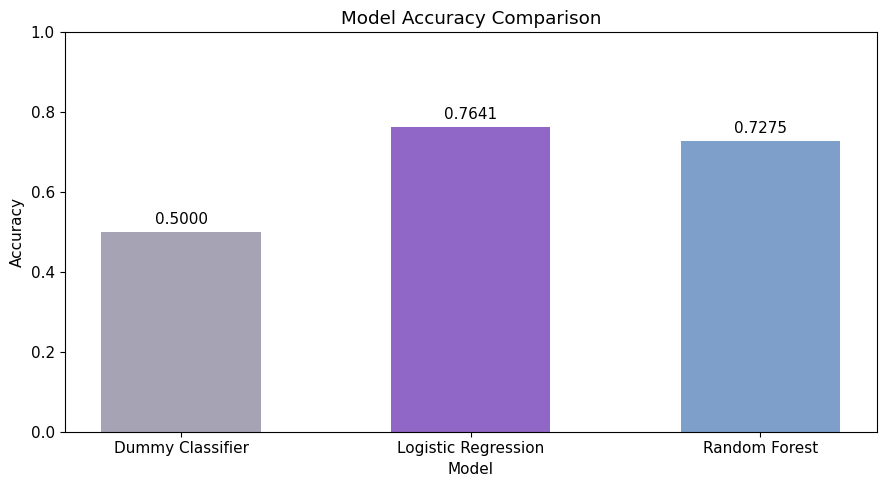

In [13]:
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(results["Model"],results["accuracy"],color=[COLORS[model] for model in results["Model"]],width=0.55)

ax.set_title("Model Accuracy Comparison")
ax.set_xlabel("Model")
ax.set_ylabel("Accuracy")
ax.set_ylim(0, 1)

for bar in bars:
    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.02,
        f"{height:.4f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

### Interpretation

Logistic Regression achieves the highest accuracy at 76.4%, followed by Random Forest at 72.7%. The Dummy Classifier reaches 50%, as expected for the balanced test set.

Both Logistic Regression and Random Forest outperform the baseline, suggesting that the selected features provide useful information for distinguishing between benign and pathogenic variants.

However, accuracy does not show how often each model misclassifies benign or pathogenic variants. Precision, recall, and F1-score are therefore needed for a more complete comparison.

## 5. Precision, Recall, and F1-score

Precision and recall help assess how well each model identifies pathogenic variants.

High precision indicates that most variants predicted as pathogenic are correctly classified, although some pathogenic variants may still be missed.

Higher recall means that more pathogenic variants are identified, but this may also lead to more benign variants being incorrectly classified as pathogenic.

The F1-score balances precision and recall, allowing the models to be compared using a single measure that accounts for both types of performance.

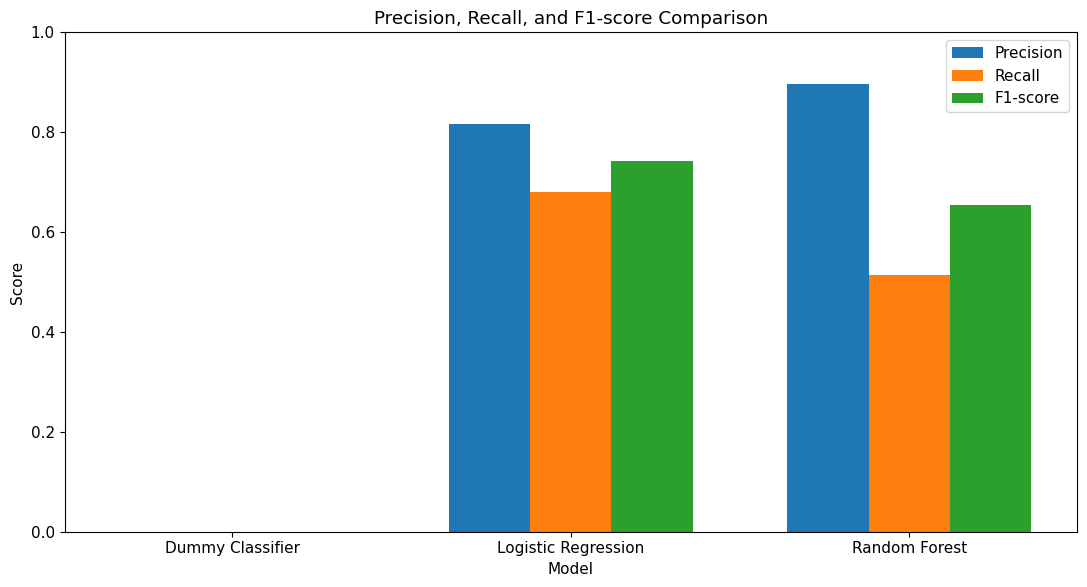

In [5]:
comparison_metrics = [
    "precision_pathogenic",
    "recall_pathogenic",
    "f1_pathogenic"
]

comparison_labels = [
    "Precision",
    "Recall",
    "F1-score"
]

x = np.arange(len(results))
width = 0.24

fig, ax = plt.subplots(figsize=(11, 6))

for index, (metric, label) in enumerate(
    zip(comparison_metrics, comparison_labels)
):
    ax.bar(
        x + (index - 1) * width,
        results[metric],
        width,
        label=label
    )

ax.set_title("Precision, Recall, and F1-score Comparison")
ax.set_xlabel("Model")
ax.set_ylabel("Score")
ax.set_xticks(x)
ax.set_xticklabels(results["Model"])
ax.set_ylim(0, 1)

ax.legend()

plt.tight_layout()
plt.show()

In [14]:
lr = results.loc[results["Model"] == "Logistic Regression"].iloc[0]

rf = results.loc[results["Model"] == "Random Forest"].iloc[0]

comparison = pd.DataFrame({
    "Metric": [
        "Precision",
        "Recall",
        "F1-score"
    ],
    "Logistic Regression": [
        lr["precision_pathogenic"],
        lr["recall_pathogenic"],
        lr["f1_pathogenic"]
    ],
    "Random Forest": [
        rf["precision_pathogenic"],
        rf["recall_pathogenic"],
        rf["f1_pathogenic"]
    ]
})

comparison["Difference (LR - RF)"] = (comparison["Logistic Regression"] - comparison["Random Forest"])

comparison.round(4)

,Metric,Logistic Regression,Random Forest,Difference (LR - RF)
0,Precision,0.8173,0.8973,-0.0800
1,Recall,0.6803,0.5137,0.1666
2,F1-score,0.7425,0.6534,0.0892


### Interpretation

Random Forest achieves higher precision for the pathogenic class than Logistic Regression, but its recall is considerably lower. This means that a smaller proportion of its pathogenic predictions are false positives, while more pathogenic variants are incorrectly classified as benign.

Logistic Regression achieves a better balance between precision and recall, resulting in a higher F1-score. Based on this metric, it is the preferred model for the current classification task.

However, these results do not establish which model would be more appropriate for clinical use. Such a decision would require assessing the consequences of false-positive and false-negative predictions and determining which errors should be prioritized.

## 6. ROC-AUC and PR-AUC Comparison

ROC-AUC and PR-AUC assess model performance across different classification thresholds rather than at a single threshold.

ROC-AUC measures how well a model distinguishes between benign and pathogenic variants by comparing the true-positive and false-positive rates.

PR-AUC describes the relationship between precision and recall as the classification threshold changes.

Together, these metrics provide additional information about model performance beyond accuracy and F1-score, which are calculated using a specific classification threshold.

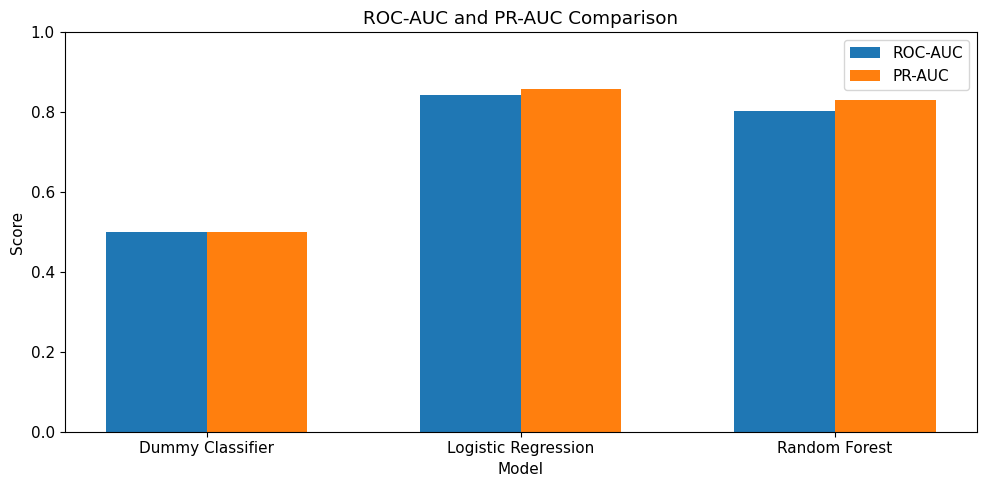

In [15]:
auc_metrics = ["roc_auc","pr_auc"]

auc_labels = ["ROC-AUC","PR-AUC"]

x = np.arange(len(results))
width = 0.32

fig, ax = plt.subplots(figsize=(10, 5))

for index, (metric, label) in enumerate(zip(auc_metrics, auc_labels)):
    ax.bar(
        x + (index - 0.5) * width,
        results[metric],
        width,
        label=label
    )

ax.set_title("ROC-AUC and PR-AUC Comparison")
ax.set_xlabel("Model")
ax.set_ylabel("Score")
ax.set_xticks(x)
ax.set_xticklabels(results["Model"])
ax.set_ylim(0, 1)

ax.legend()

plt.tight_layout()
plt.show()

### Interpretation

Logistic Regression achieves higher ROC-AUC and PR-AUC scores than Random Forest, indicating better discrimination between benign and pathogenic variants and a stronger precision–recall relationship across classification thresholds.

The Dummy Classifier provides a baseline for comparison but cannot meaningfully distinguish between the two classes.

Since the test set contains equal numbers of benign and pathogenic variants, the reported PR-AUC values reflect performance under this balanced distribution. They should not be assumed to represent performance in datasets where pathogenic variants occur at different frequencies.

## 7. Receiver Operating Characteristic Curves

The ROC curve shows how the true-positive rate (recall) changes relative to the false-positive rate at different classification thresholds.

A curve closer to the upper-left corner indicates better discrimination between benign and pathogenic variants. The diagonal line represents the performance of a classifier with no ability to distinguish between the two classes.

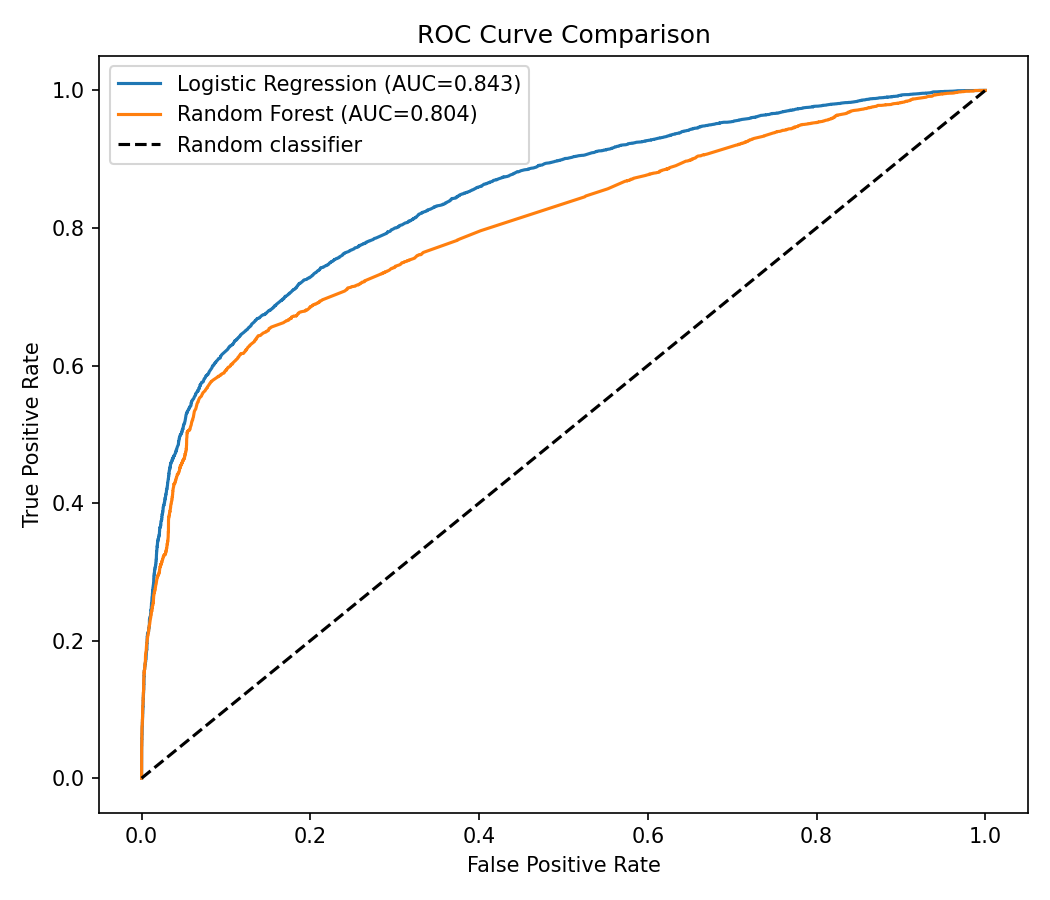

In [8]:
roc_path = FIGURES_DIR / "roc_curve_comparison.png"

if roc_path.exists():
    display(Image.open(roc_path))
else:
    print(f"Figure not found: {roc_path}")

## 8. Precision–Recall Curves

Precision–Recall curves show how precision changes with recall as the classification threshold varies.

They help assess how effectively each model identifies pathogenic variants while limiting the number of benign variants incorrectly classified as pathogenic.

The baseline precision depends on the proportion of pathogenic variants in the test set, which is 50% in this dataset.

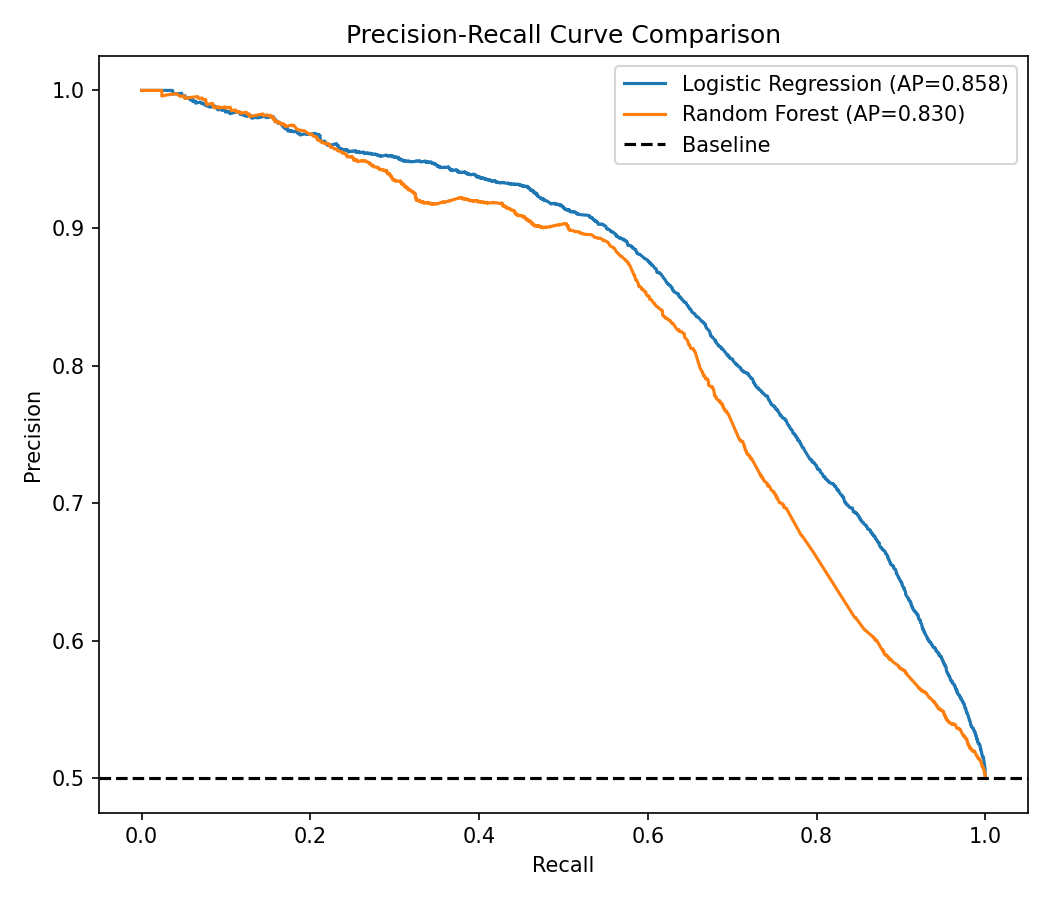

In [9]:
pr_path = FIGURES_DIR / "precision_recall_comparison.png"

if pr_path.exists():
    display(Image.open(pr_path))
else:
    print(f"Figure not found: {pr_path}")

## 9. Confusion Matrix Analysis

A confusion matrix shows how many variants are correctly and incorrectly classified in each class. It contains four possible outcomes:

- **True Negative (TN):** A benign variant correctly classified as benign.
- **False Positive (FP):** A benign variant incorrectly classified as pathogenic.
- **False Negative (FN):** A pathogenic variant incorrectly classified as benign.
- **True Positive (TP):** A pathogenic variant correctly classified as pathogenic.

Unlike accuracy, the confusion matrix shows which types of classification errors each model makes.

False negatives are particularly important to examine in this task because they represent pathogenic variants that the model fails to identify.

The following confusion matrices were generated by the evaluation pipeline.

Confusion Matrix


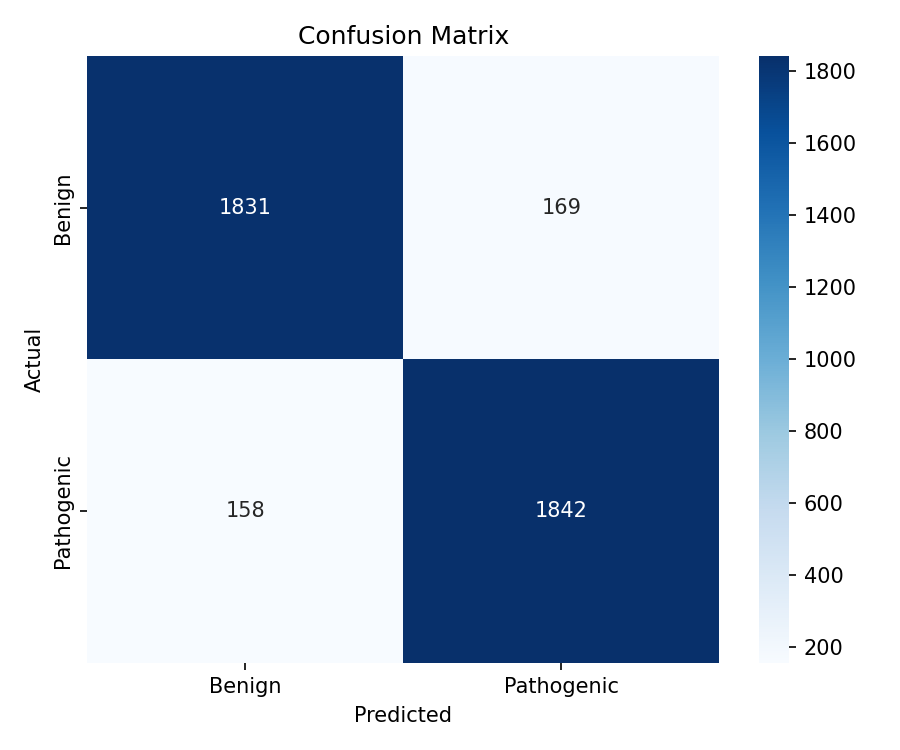

Logistic Regression Confusion Matrix


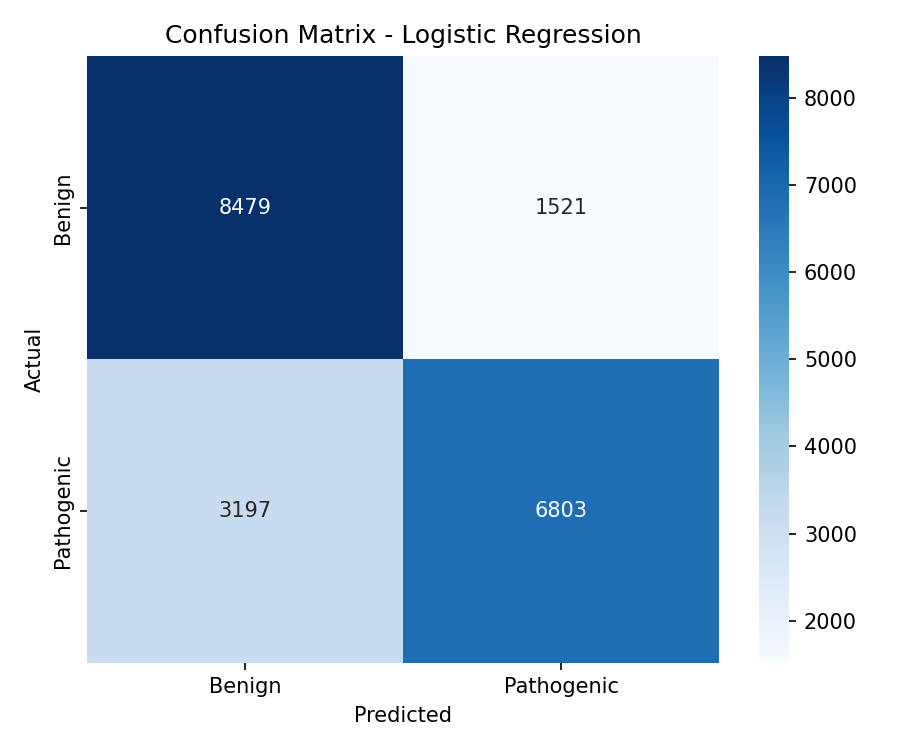

Random Forest Confusion Matrix


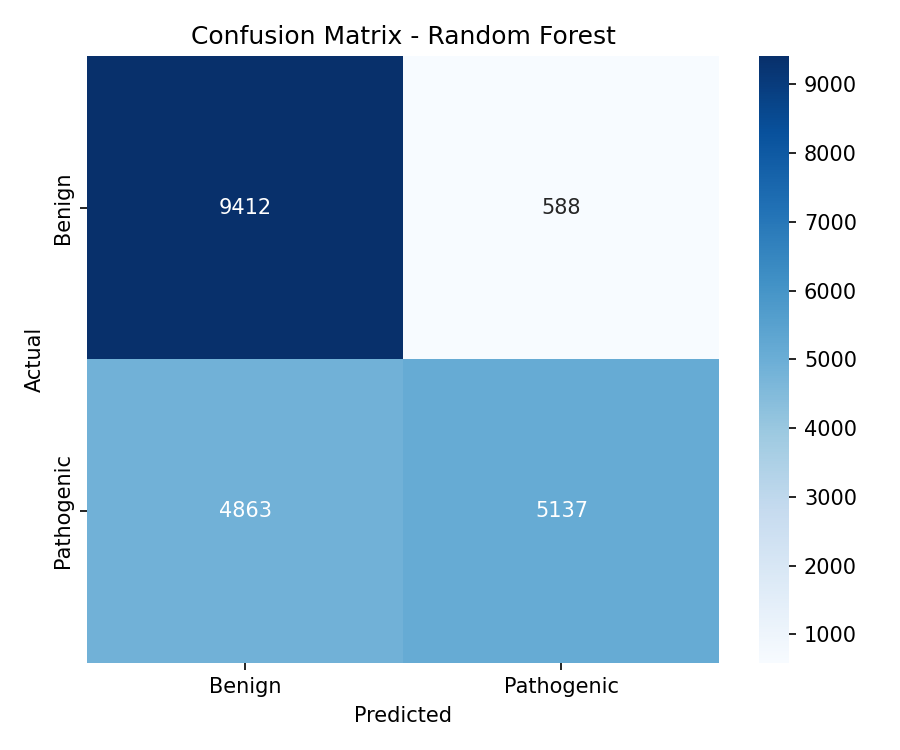

In [10]:
confusion_files = sorted(
    path
    for path in FIGURES_DIR.glob("*.png")
    if "confusion" in path.name.lower()
)

if confusion_files:

    for file_path in confusion_files:
        print(file_path.stem.replace("_", " ").title())
        display(Image.open(file_path))

else:
    print("No confusion matrix figures found.")

### Interpretation

The confusion matrices show how the models differ in their classification errors.

The Dummy Classifier serves as a baseline and does not use the variants' genomic features to distinguish between classes.

Logistic Regression correctly identifies a larger proportion of pathogenic variants than Random Forest. Random Forest achieves higher precision for pathogenic predictions but misses more pathogenic variants, resulting in a higher number of false negatives.

These differences show why accuracy alone cannot fully describe model performance. The importance of each error type depends on how the predictions are intended to be used.

## 10. Model Ranking

The models are ranked by their F1-score for the pathogenic class, which serves as the main selection criterion because it accounts for both precision and recall.

ROC-AUC and PR-AUC are also considered to assess how well each model distinguishes between benign and pathogenic variants across classification thresholds.

The ranking reflects performance on the current test set and may differ with other datasets, features, or evaluation procedures.

In [16]:
model_ranking = (results.sort_values(by="f1_pathogenic",ascending=False).reset_index(drop=True))

model_ranking.index = model_ranking.index + 1
model_ranking.index.name = "Rank"

model_ranking[
    [
        "Model",
        "accuracy",
        "f1_pathogenic",
        "roc_auc",
        "pr_auc"
    ]
].round(4)

,Model,accuracy,f1_pathogenic,roc_auc,pr_auc
Rank,,,,,
1,Logistic Regression,0.7641,0.7425,0.8431,0.8578
2,Random Forest,0.7274,0.6534,0.8039,0.8301
3,Dummy Classifier,0.5000,0.0000,0.5000,0.5000


In [12]:
best_model = model_ranking.iloc[0]

print("Best Performing Model")
print("-" * 35)

print("Model:", best_model["Model"])
print("Accuracy: {:.4f}".format(best_model["accuracy"]))
print("Precision: {:.4f}".format(best_model["precision_pathogenic"]))
print("Recall: {:.4f}".format(best_model["recall_pathogenic"]))
print("F1-score: {:.4f}".format(best_model["f1_pathogenic"]))
print("ROC-AUC: {:.4f}".format(best_model["roc_auc"]))
print("PR-AUC: {:.4f}".format(best_model["pr_auc"]))

Best Performing Model
-----------------------------------
Model: Logistic Regression
Accuracy: 0.7641
Precision: 0.8173
Recall: 0.6803
F1-score: 0.7425
ROC-AUC: 0.8431
PR-AUC: 0.8578


## 11. Discussion

Logistic Regression achieves the best overall performance among the three evaluated models, with the highest accuracy, F1-score, ROC-AUC, and PR-AUC.

Random Forest produces more precise predictions for the pathogenic class but has lower recall, meaning that it fails to identify a larger proportion of pathogenic variants.

The results suggest that Logistic Regression can make effective use of the selected features, despite its relatively simple linear structure. However, this does not mean that linear models are generally better suited to genetic variant classification. Performance depends on the available data, feature representation, preprocessing methods, and model configuration.

The findings support selecting Logistic Regression for the current project, while several limitations need to be considered when interpreting its performance.

### Limitations

**Balanced dataset**

The dataset contains equal numbers of benign and pathogenic variants. This distribution may not reflect the prevalence of pathogenic variants in real-world applications. As a result, precision, PR-AUC, and predicted probabilities may differ when the model is applied to datasets with different class distributions.

**Limited feature representation**

The models use chromosome and gene identifiers, mutation types, allele lengths, and origin metadata. They do not include potentially informative features such as evolutionary conservation, functional annotations, population allele frequencies, or predicted protein effects. These omissions may limit their ability to distinguish between variants with similar basic characteristics.

**Potential gene-level dependencies**

The stratified random split may place variants from the same gene in both the training and test sets. The reported results therefore describe performance on randomly held-out variants rather than on entirely unseen genes. Evaluating the models using a gene-based split would provide a clearer picture of how well they generalize across genes.

**Clinical interpretation**

The models were developed for experimental classification and have not undergone clinical validation. Their performance on the current test set does not establish their reliability in clinical settings, and their predictions should not be used for diagnosis or medical decision-making.

## 12. Summary and Conclusions

This notebook compared three classification models using a balanced dataset of 100,000 ClinVar variants.

### Main Findings

Logistic Regression and Random Forest both outperform the Dummy Classifier baseline. Logistic Regression achieves the highest accuracy, F1-score, ROC-AUC, and PR-AUC, while Random Forest has higher precision but lower recall for pathogenic variants.

The confusion matrices show how these differences affect classification errors, particularly the number of pathogenic variants incorrectly classified as benign.

### Selected Model

**Logistic Regression** is selected as the preferred model for this project, primarily because it achieves the highest F1-score for the pathogenic class. Its accuracy and performance across classification thresholds further support this choice.

However, these results are specific to the current dataset and evaluation procedure. They do not establish the model's suitability for clinical use.

### Next Steps

The next notebook, `03_experimental_analysis.ipynb`, examines how individual features and feature groups contribute to model predictions. It includes an analysis of Logistic Regression coefficients, Random Forest feature importance, and feature-group ablation experiments.

It also evaluates model generalization using a gene-based train-test split, where genes in the test set are excluded from training. This provides an additional assessment of performance on variants from previously unseen genes.